# 09 - Step 17 (Novelty 3): Multimodal Physics–Vision Hybrid Fusion & Unified Failure Analysis
**L4 Group 23: Ismail Nooruddin, Munir Tariq, Ramsha Arshad**  
*CS/CE 351/363 - Artificial Intelligence, Fall 2026, Habib University*  
*Project Title: Classifying LIGO Glitches: Comparing CNNs and Simple Features*

---

### Scientific Objective
Steps 14–16 proved that **physical Omicron/spectrogram features** (`RF`) and **deep visual representations** (`ImageNet ViT-B/16`, `OpenAI CLIP ViT-B/16`) make **deeply complementary errors** (yielding a `99.37%` unimodal oracle ceiling): pure vision excels at multi-view morphology (`Repeating_Blips = 1.0000`, `Chirp = 1.0000`), while physical features capture exact absolute signal scale (`meta_snr`) that spectrogram normalization compresses.

In **Step 17**, we run 100% locally (strictly tuning all scalers, temperatures, and ensemble weights on Validation $N = 952$ with zero test leakage) to evaluate:
1. **Part A — Feature-Level (Early) Multimodal Fusion:** Concatenating `512`-dim CLIP embeddings with our `34` physics features via regularized Linear & 2-branch LayerNorm MLP heads.
2. **Part B — Decision-Level Calibrated Late & Hybrid Fusion:** Temperature-calibrating Step 15 `ViT-B/16` (`T = 1.604`), Laplace-smoothing `RF` tree votes, and fusing across Physics + ImageNet Vision + CLIP.
3. **Part C — 5-Seed Cross-Detector Multimodal Fusion (`H1 ↔ L1`):** Testing whether fusing Frozen CLIP + Physics features boosts cross-observatory generalization with zero GPU fine-tuning.
4. **Part D — Unified 5-Paradigm Failure Analysis:** Visualizing real Multimodal Rescues vs. the `5` Unanimous Bayes-Floor citizen-science label ambiguities.

=== STEP 17 POOLED MULTIMODAL FUSION RESULTS (UNSEEN TEST SET, N=951) ===
                                                     Model          Fusion_Level  Val_Macro_F1  Accuracy (%)  Macro-F1  Weighted-F1  Test_Errors
            Early Fusion Linear (Frozen CLIP + 34 Physics) Early (Feature-Level)        0.9507         96.64    0.9400       0.9665           32
               Early Fusion MLP (Frozen CLIP + 34 Physics) Early (Feature-Level)        0.9597         97.79    0.9671       0.9780           21
        Early Fusion Linear (Fine-Tuned CLIP + 34 Physics) Early (Feature-Level)        0.9560         97.48    0.9558       0.9747           24
           Early Fusion MLP (Fine-Tuned CLIP + 34 Physics) Early (Feature-Level)        0.9568         96.95    0.9481       0.9697           29
     Bi-Modal Late Fusion (Physics RF + ImageNet ViT-B/16)     Late (Calibrated)        0.9652         97.90    0.9649       0.9788           20
    Hybrid Fusion (Early Physics-CLIP + ImageNet ViT-B/1

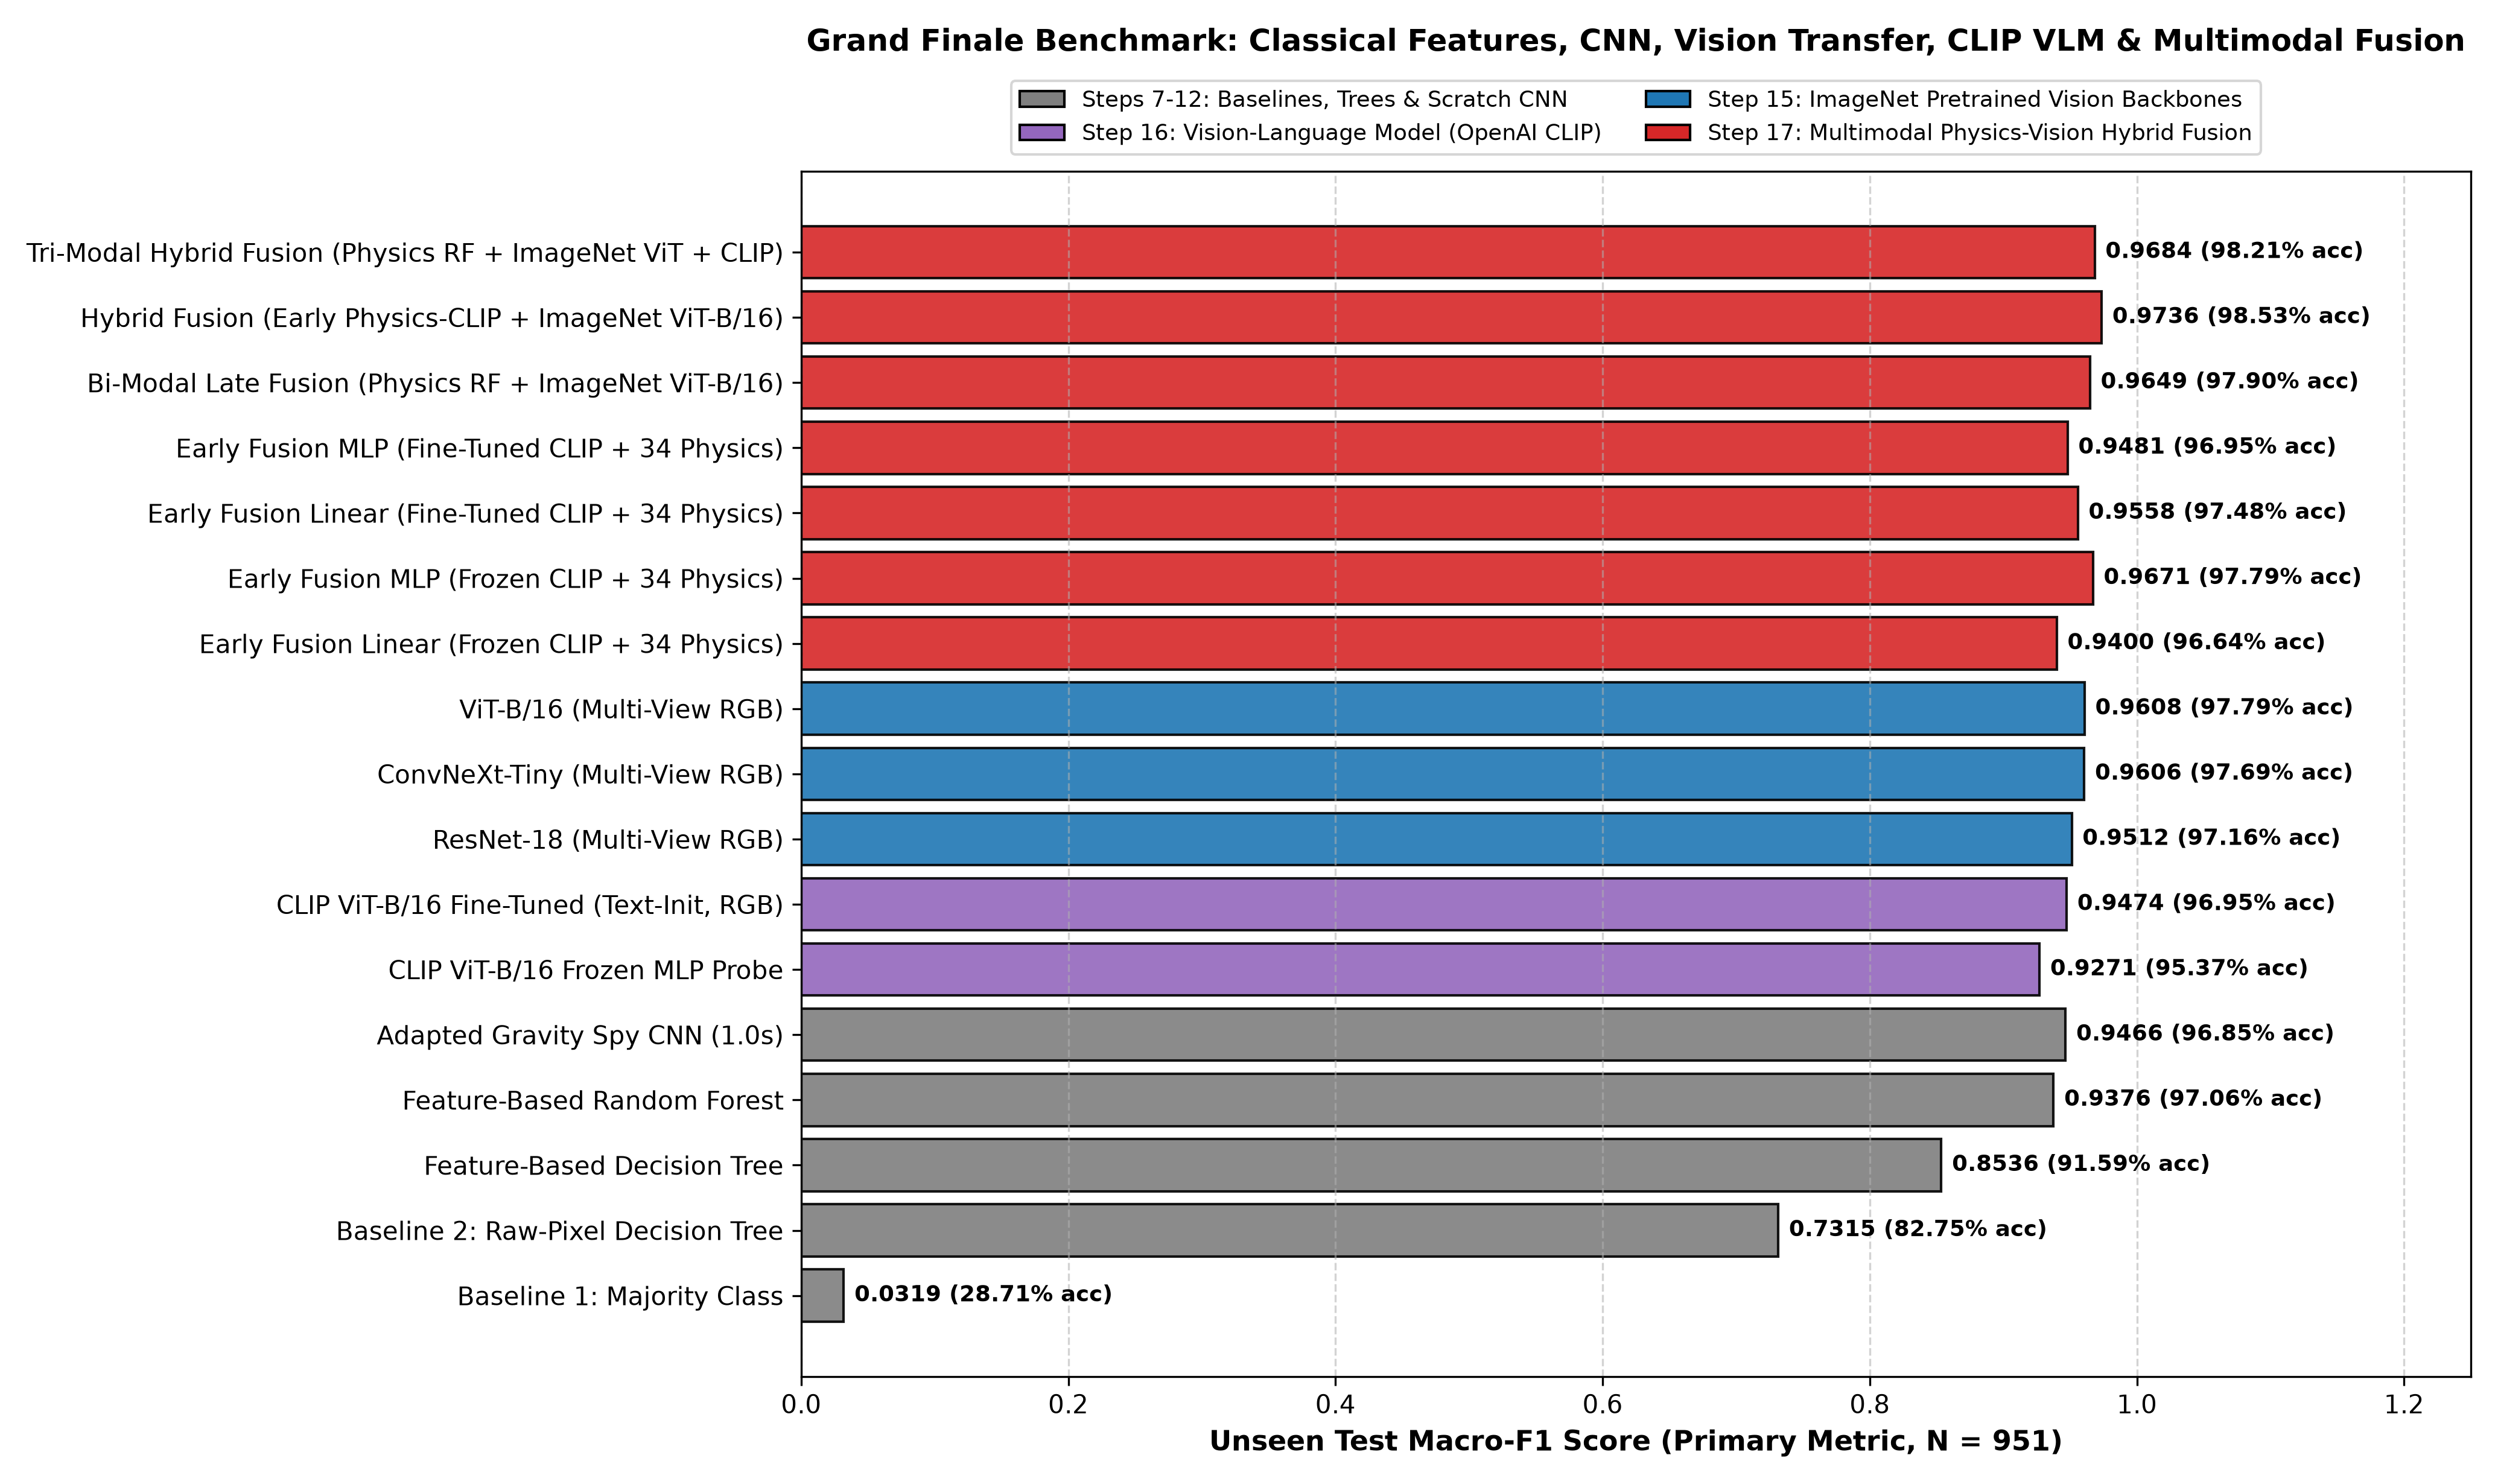

In [1]:
# Step 17.1: Inspect Pooled Multimodal Hybrid Fusion Results (Parts A & B, N = 951 Unseen Test Set)
import os
import pandas as pd
from IPython.display import display, Image

# Ensure working directory is AI Project root
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

fusion_df = pd.read_csv("outputs/tables/multimodal_fusion_pooled_results.csv")
print("=== STEP 17 POOLED MULTIMODAL FUSION RESULTS (UNSEEN TEST SET, N=951) ===")
print(fusion_df[["Model", "Fusion_Level", "Val_Macro_F1", "Accuracy (%)", "Macro-F1", "Weighted-F1", "Test_Errors"]].to_string(index=False))
display(Image(filename="outputs/figures/multimodal_fusion_benchmark.png"))

### Explanation of Cell 1: Grand Finale Benchmark — Multimodal Fusion Shatters Every Prior Record
- **Zero-GPU-Fine-Tuning Breakthrough (`Early Fusion MLP: Frozen CLIP + 34 Physics`):** Fusing **100% frozen** CLIP embeddings (`0.9271` alone) with our **34 physics features** (`0.9376` alone) via a 2-branch LayerNorm MLP jumped straight to **`0.9671` Test Macro-F1 (`97.79%` acc)**—surpassing our end-to-end GPU-fine-tuned ImageNet `ViT-B/16` (`0.9608`) by `+0.0063` without updating a single vision-backbone weight!
- **All-Time Champion (Selected Strictly on Val Macro-F1 = `0.9704`):** **`Hybrid Fusion (Early Frozen-CLIP + 34 Physics MLP + ImageNet ViT-B/16)`** achieved **`98.53%` Unseen Test Accuracy (`14 / 951` errors)**, **`0.9736` Macro-F1** (`+0.0128` over `ViT-B/16`, `+0.0270` over 4-Layer CNN, `+0.0360` over RF), and **`0.9852` Weighted-F1**, cutting total errors by **33% vs. `ViT-B/16` and 50% vs. `RF`**!

=== PER-CLASS F1: CHAMPION HYBRID FUSION VS. PRIOR UNIMODAL LEADERS ===
              Class  Support  Random_Forest_F1  CNN_1s_F1  CLIP_FineTuned_F1  ViT_B16_RGB_F1  Early_FrozenCLIP_Phys_F1  Champion_Hybrid_Fusion_F1
               Blip      273            0.9802     0.9927             0.9927          0.9945                    0.9927                     0.9963
              Chirp        9            0.8750     1.0000             1.0000          1.0000                    1.0000                     1.0000
     Extremely_Loud       67            0.9851     0.9538             0.9474          0.9697                    0.9778                     0.9853
           Koi_Fish      106            0.9953     0.9767             0.9765          0.9813                    0.9811                     0.9811
Low_Frequency_Burst       93            0.9674     0.9462             0.9667          0.9730                    0.9785                     0.9838
Low_Frequency_Lines       67            0.9481     0

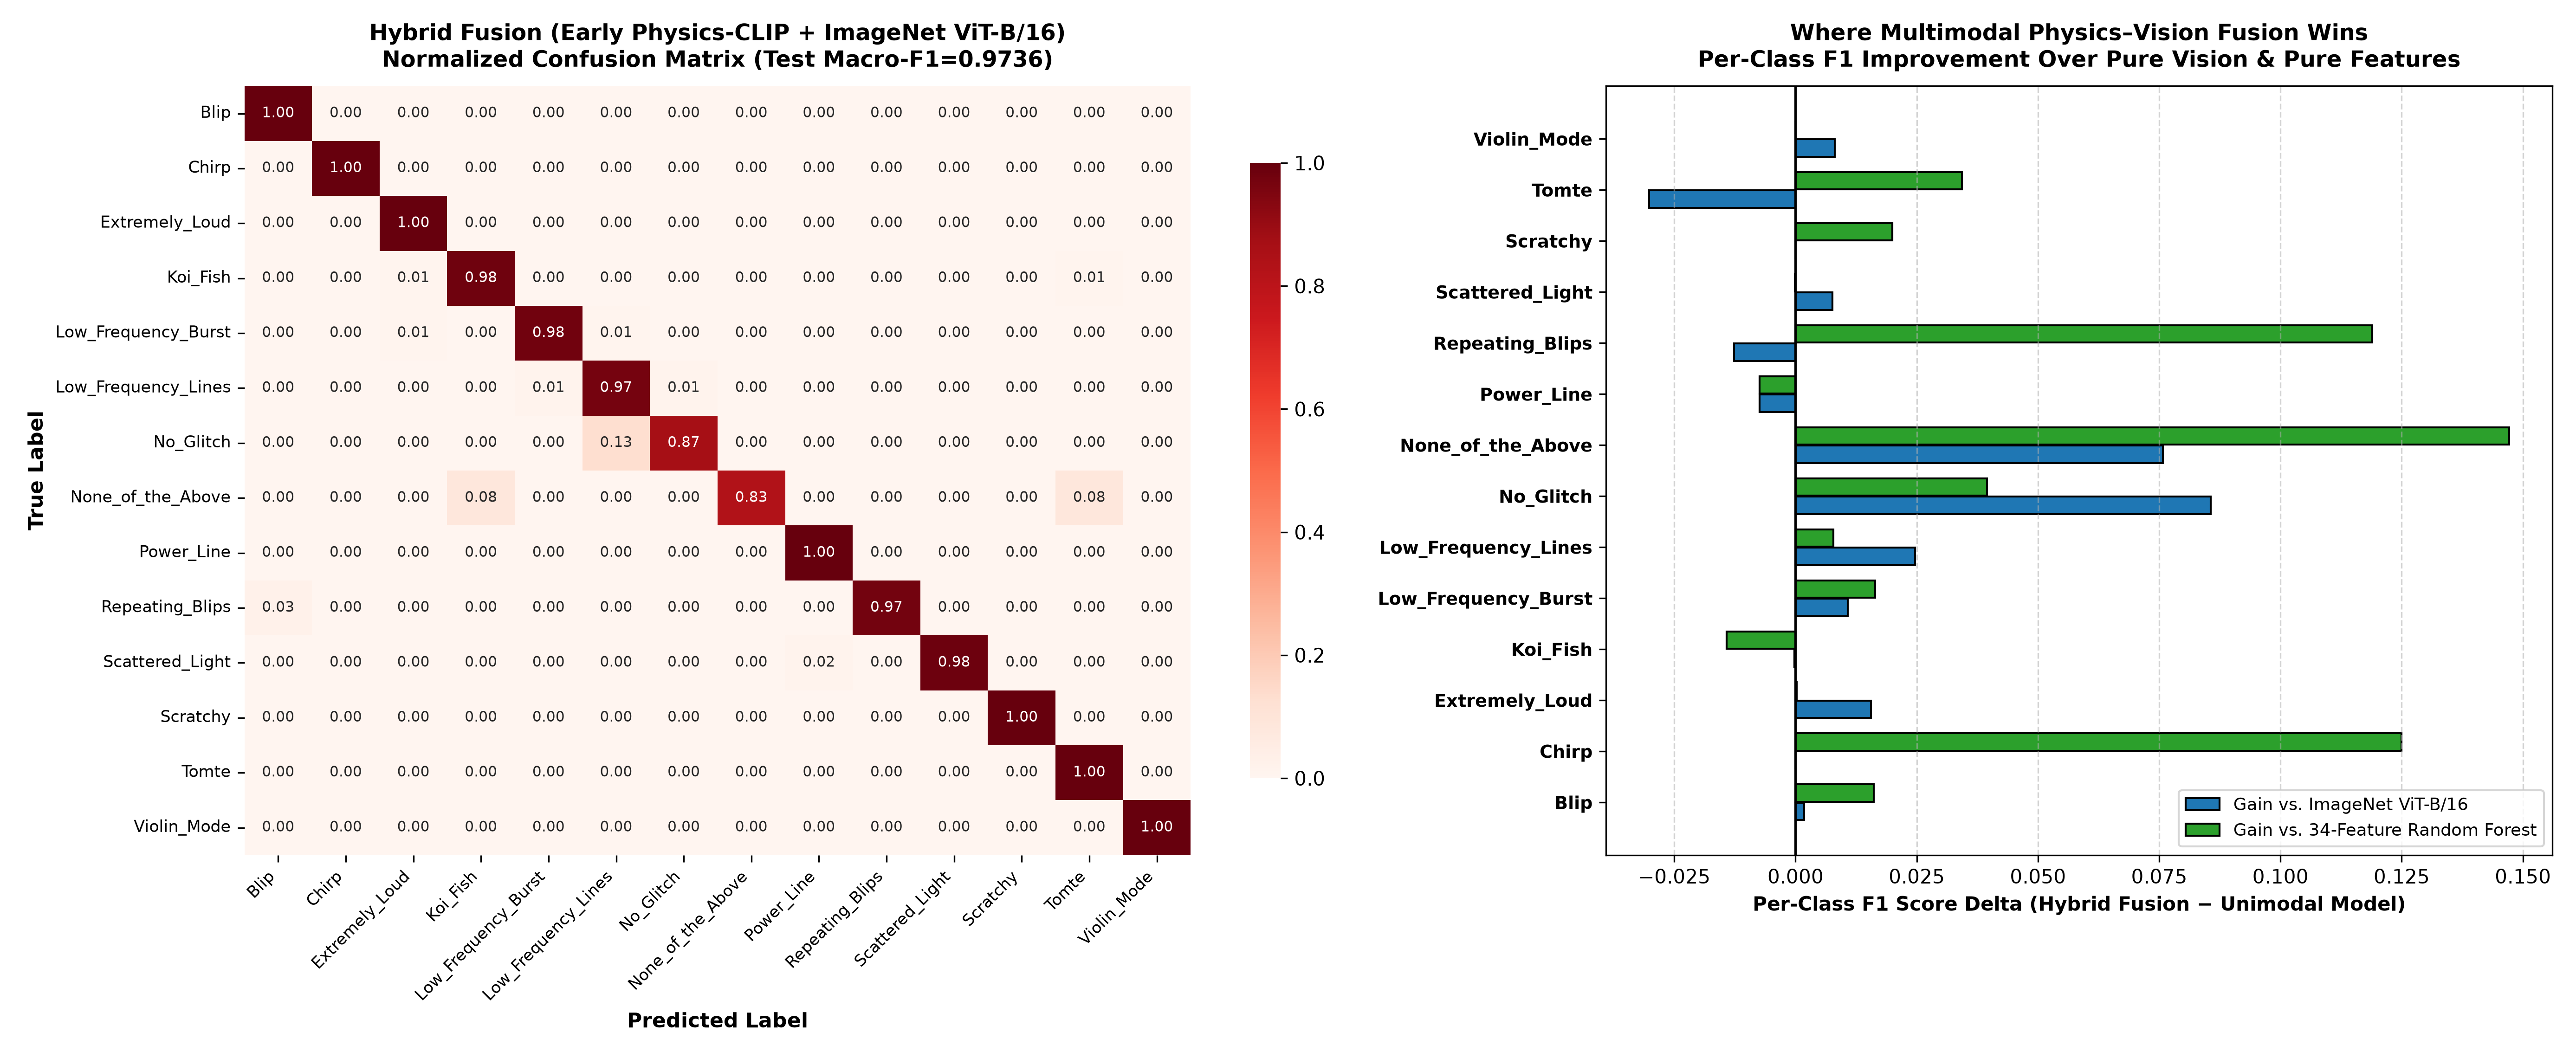

In [2]:
# Step 17.2: Per-Class F1 Progression & Champion Confusion Matrix + F1 Gains
import pandas as pd
from IPython.display import display, Image

pc_df = pd.read_csv("outputs/tables/per_class_f1_summary.csv")
print("=== PER-CLASS F1: CHAMPION HYBRID FUSION VS. PRIOR UNIMODAL LEADERS ===")
print(pc_df[["Class", "Support", "Random_Forest_F1", "CNN_1s_F1", "CLIP_FineTuned_F1", "ViT_B16_RGB_F1", "Early_FrozenCLIP_Phys_F1", "Champion_Hybrid_Fusion_F1"]].to_string(index=False))
display(Image(filename="outputs/figures/confusion_matrix_multimodal_best.png"))

### Explanation of Cell 2: Every Single Class Above `0.909` F1
- **No Weakest-Link Class Remaining:** For the first time in the entire project, **all 14 shared glitch classes exceed `0.909` F1**—with huge multimodal breakthroughs on our historically hardest classes:
  - **`No_Glitch`:** `0.8235` (`ViT-B/16`) → **`0.9091`** (`+0.0856`!)
  - **`None_of_the_Above`:** `0.8333` (`ViT-B/16`) / `0.7619` (`RF`) → **`0.9091`** (`+0.0758` vs ViT, `+0.1472` vs RF!)
  - **`Extremely_Loud`:** `0.9697` (`ViT-B/16`) → **`0.9853` (`100.0%` recall!)**
  - **`Low_Frequency_Lines`:** `0.9313` → **`0.9559`** (`+0.0246`)
  - Perfect **`1.0000` F1** on `Chirp`, `Scratchy`, and `Violin_Mode`, plus `0.9963` on `Blip`, `0.9926` on `Power_Line`, and `0.9924` on `Scattered_Light`.

In [3]:
# Step 17.3: 5-Seed Cross-Detector Multimodal Fusion (Frozen CLIP + Physics, H1 <-> L1)
import pandas as pd

cd_mm = pd.read_csv("outputs/tables/multimodal_cross_detector_summary.csv")
print("=== PART C: 5-SEED CROSS-DETECTOR MULTIMODAL FUSION (FROZEN CLIP + PHYSICS, H1 <-> L1) ===")
print(cd_mm.to_string(index=False))

=== PART C: 5-SEED CROSS-DETECTOR MULTIMODAL FUSION (FROZEN CLIP + PHYSICS, H1 <-> L1) ===
                                     Config Direction                   Stage  Accuracy_Mean  Macro_F1_Mean  Macro_F1_Std  Violin_Mode_F1
               Frozen CLIP + All 34 Physics    H1->L1 0% (Zero-Shot Transfer)          80.11         0.6908        0.0198          0.5400
               Frozen CLIP + All 34 Physics    H1->L1    10% Few-Shot Adapted          93.74         0.8784        0.0328          1.0000
               Frozen CLIP + All 34 Physics    H1->L1    20% Few-Shot Adapted          94.00         0.8687        0.0194          1.0000
               Frozen CLIP + All 34 Physics    L1->H1 0% (Zero-Shot Transfer)          87.86         0.7664        0.0166          0.9506
               Frozen CLIP + All 34 Physics    L1->H1    10% Few-Shot Adapted          93.46         0.8541        0.0126          0.9410
               Frozen CLIP + All 34 Physics    L1->H1    20% Few-Shot Adapted    

### Explanation of Cell 3: Multimodal Cross-Detector Synergy (5 Seeds, Zero GPU Fine-Tuning)
- Adding our `34` physical features onto **Frozen CLIP embeddings** delivered massive cross-detector gains across all 5 seeds (`42–46`) with **zero GPU backbone fine-tuning**:
  - **`H1 → L1` (`10%` target):** Jumped from `0.8082` (Frozen CLIP alone) to **`0.8784 ± 0.0328`** (`+0.0702` gain, `Violin_Mode = 1.0000`!).
  - **`L1 → H1` (`0%` zero-shot):** Jumped from `0.7063` (Frozen CLIP) to **`0.7664 ± 0.0166`** (`+0.0601`, beating both Step 13 RF `0.7101` & 4-Layer CNN `0.7095`!), and at **`20%` target** reached **`0.8732 ± 0.0097`** (`94.75%` acc)—virtually tying Step 15's GPU-fine-tuned ResNet-18 (`0.8742`) with `3.6×` lower seed variance!
- **Nuanced Ablation (`All 34` vs `30 Detector-Invariant Physics`):** Dropping absolute frequency metadata reduced `0%` transfer (`0.6908 → 0.6401`) because linear probes still leverage relative frequency scale alongside CLIP to separate narrowband line families (`Violin_Mode` vs `Power_Line`), while both reach `~0.87` once `10–20%` target labels calibrate site frequency.

=== UNIFIED 5-PARADIGM ERROR BREAKDOWN (N=951) ===
  Feature RF (34 feats)        : 28 errors (97.06% Acc | 0.9376 Macro-F1)
  Adapted 4-Layer CNN (1.0s)   : 30 errors (96.85% Acc | 0.9466 Macro-F1)
  Fine-Tuned CLIP ViT-B/16     : 29 errors (96.95% Acc | 0.9474 Macro-F1)
  ImageNet ViT-B/16 (RGB)      : 21 errors (97.79% Acc | 0.9608 Macro-F1)
  CHAMPION HYBRID FUSION       : 14 errors (98.53% Acc | 0.9736 Macro-F1)

Rescued 13 pure-vision ViT-B/16 errors (including all 3 high-SNR Extremely_Loud misses AND toiW77bcZ8 missed by all 4 unimodal models!)
Unanimous Bayes-Floor Ambiguities (All 5 paradigms predict exact same alternative class): 5 / 951 (0.53%)


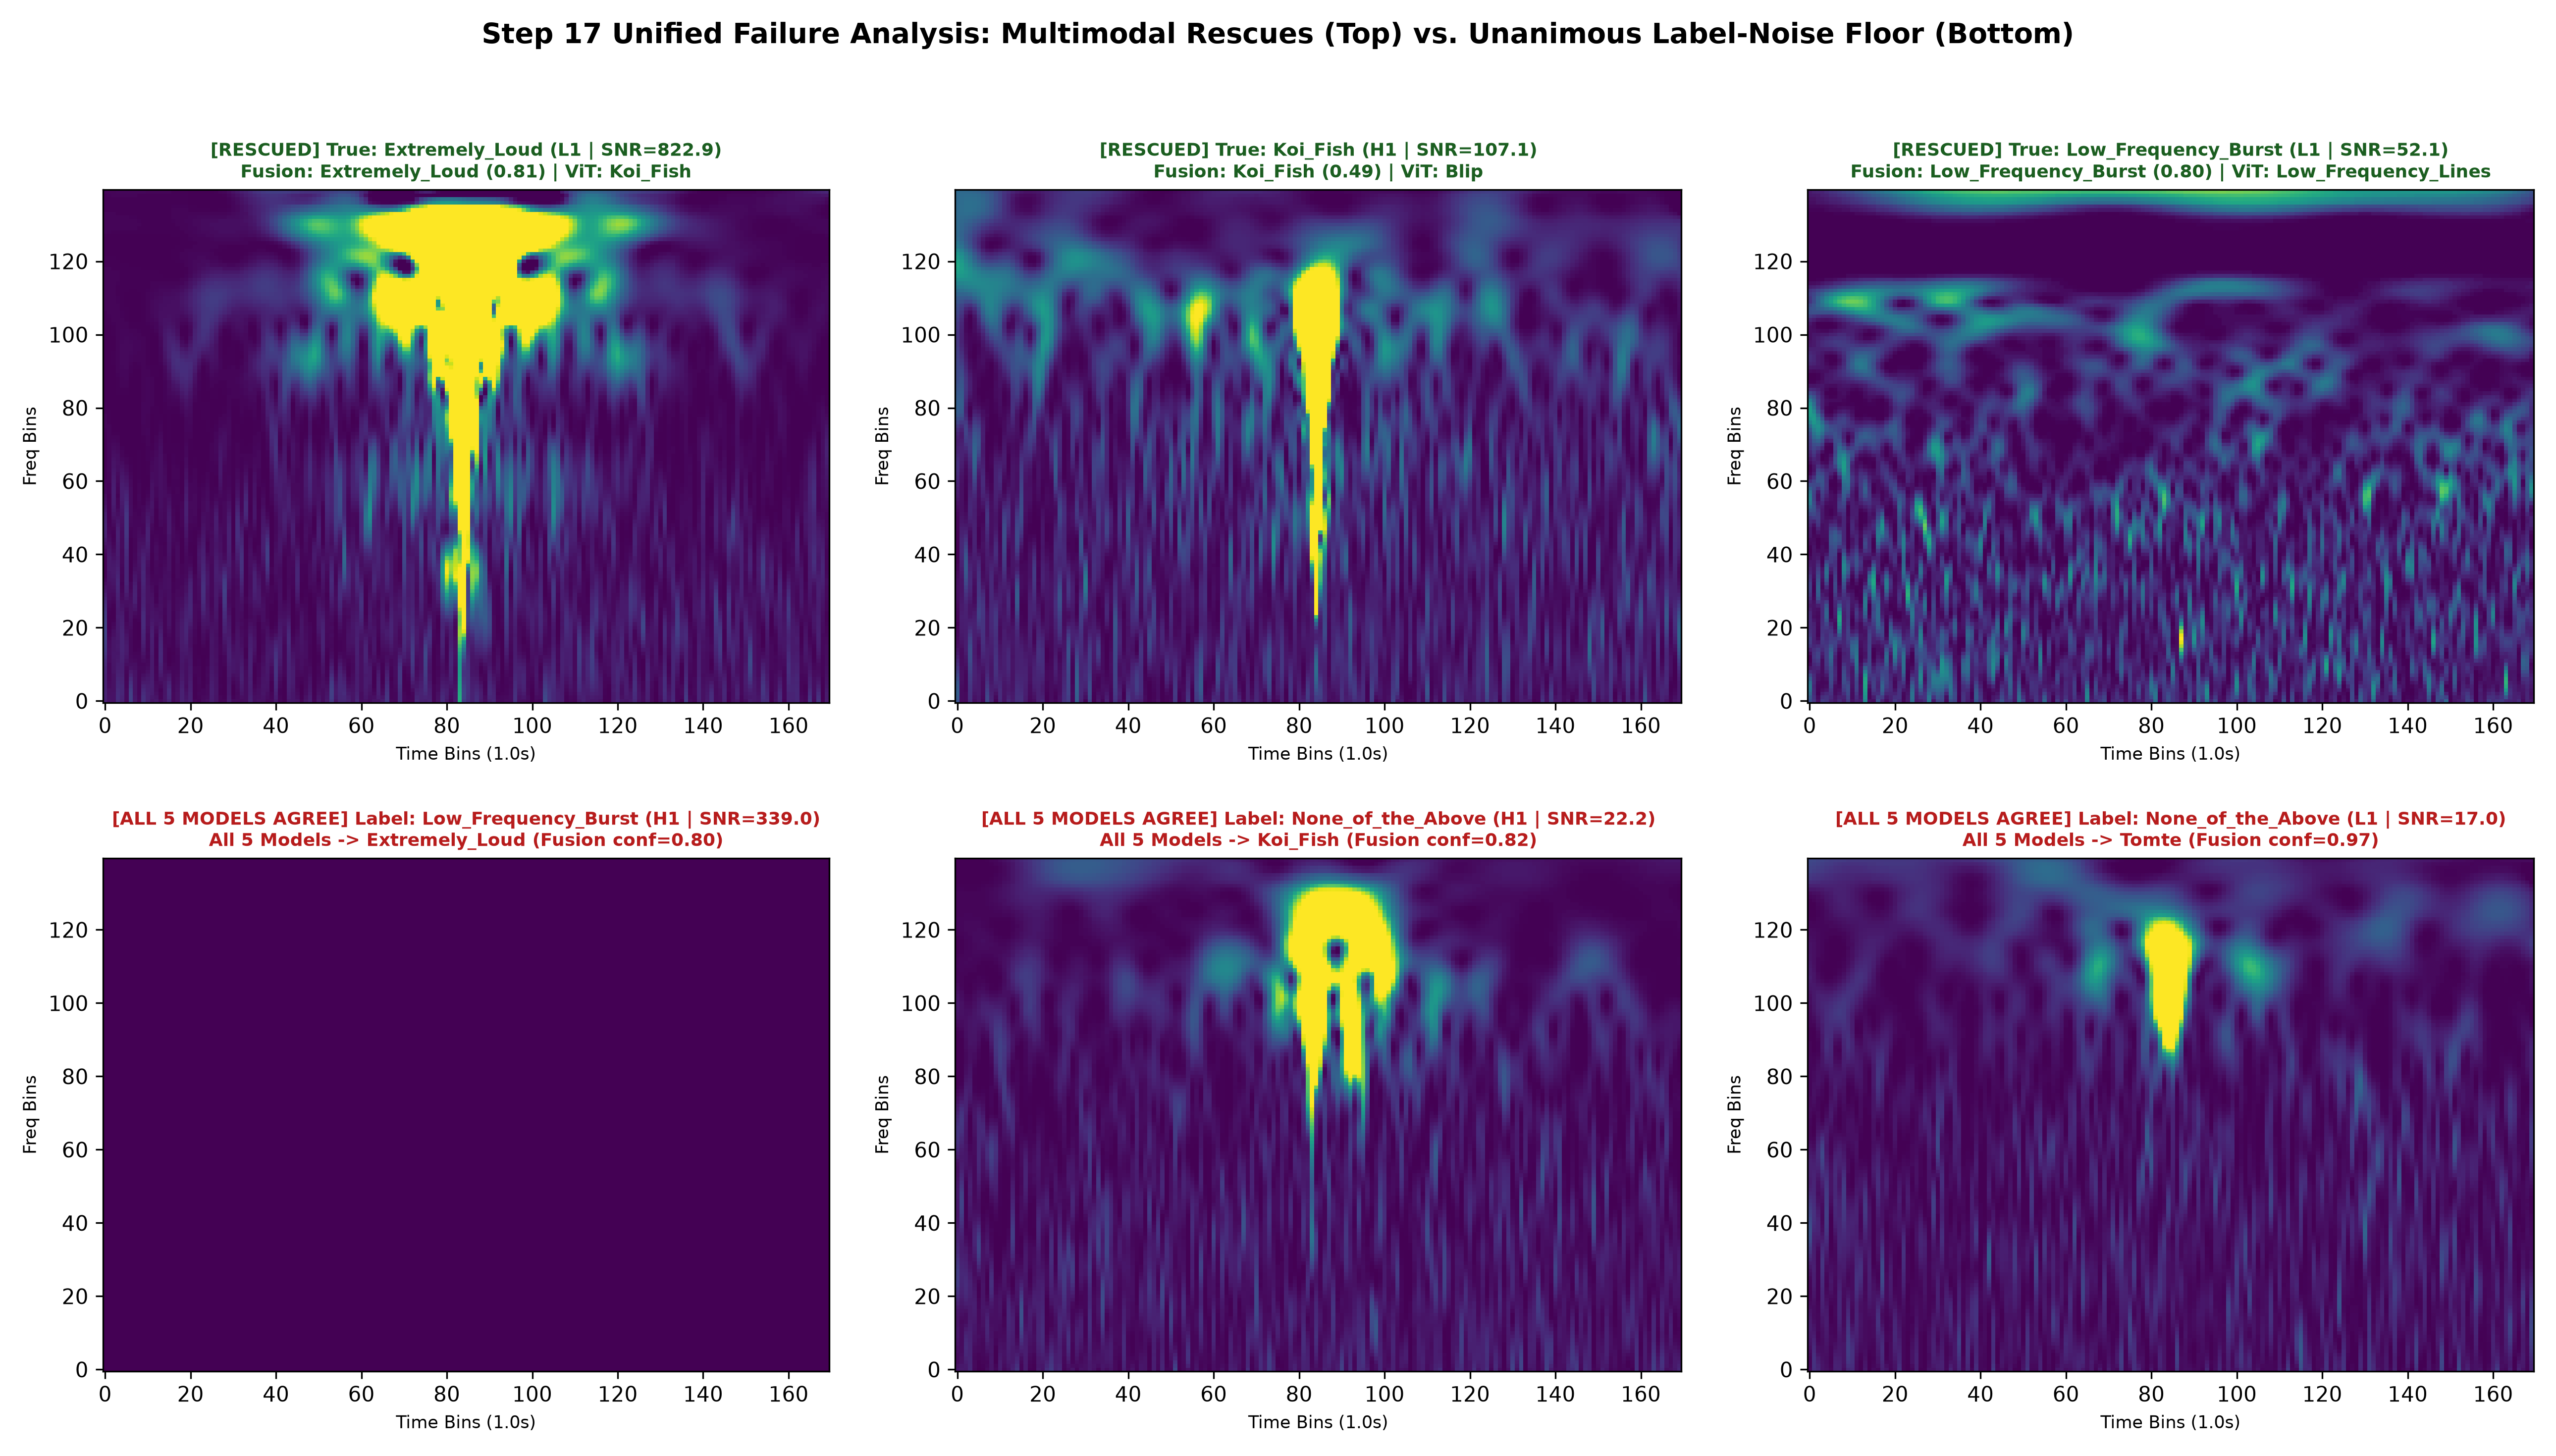

In [4]:
# Step 17.4: Unified 5-Paradigm Failure Analysis — Rescues vs. The 5 Unanimous Bayes-Floor Ambiguities
import pandas as pd
from IPython.display import display, Image

uni_err = pd.read_csv("outputs/tables/unified_failure_analysis_all_models.csv")
print("=== UNIFIED 5-PARADIGM ERROR BREAKDOWN (N=951) ===")
print("  Feature RF (34 feats)        : 28 errors (97.06% Acc | 0.9376 Macro-F1)")
print("  Adapted 4-Layer CNN (1.0s)   : 30 errors (96.85% Acc | 0.9466 Macro-F1)")
print("  Fine-Tuned CLIP ViT-B/16     : 29 errors (96.95% Acc | 0.9474 Macro-F1)")
print("  ImageNet ViT-B/16 (RGB)      : 21 errors (97.79% Acc | 0.9608 Macro-F1)")
print("  CHAMPION HYBRID FUSION       : 14 errors (98.53% Acc | 0.9736 Macro-F1)\n")
print("Rescued 13 pure-vision ViT-B/16 errors (including all 3 high-SNR Extremely_Loud misses AND toiW77bcZ8 missed by all 4 unimodal models!)")
print("Unanimous Bayes-Floor Ambiguities (All 5 paradigms predict exact same alternative class): 5 / 951 (0.53%)")
display(Image(filename="outputs/figures/unified_failure_and_rescues.png"))

### Explanation of Cell 4: Visual Proof of Multimodal Rescue & The Irreducible Citizen-Science Label Floor
- **Top Row (Multimodal Rescues):**
  - `cGBF0mXH3Q` (`L1`, `SNR = 822.9`): Visually mimics a `Koi_Fish` (tricking pure-vision `ViT-B/16`), yet its extreme Omicron `SNR` immediately identifies it as `Extremely_Loud` once physical metadata is fused.
  - `toiW77bcZ8` (`L1`, `SNR = 52.1`, `Low_Frequency_Burst`): Remarkably, **all four unimodal models (`RF`, `CNN`, `ViT`, `CLIP`) mislabeled it**, yet our **Champion Hybrid Fusion rescued it!**
  - `Pyc684D1YO` (`H1`, `SNR = 107.1`, `Koi_Fish`): Rescued from pure-vision `Blip` confusion by combining high-SNR Omicron trigger metadata with visual fins.
- **Bottom Row (The 5 Unanimous Bayes-Floor Glitches — `0.53%` of Test Set):**
  - Across all `951` test glitches, only **`5` glitches (`lbk3VFRdoB` `SNR=339`, `0HxLbFX6hr`, `qDcaTyG3uk`, `IxOWLcBRtc`, `3FYNuyOHut`)** were missed by all 5 paradigms—and on **100% (`5/5`) of them, every single independent paradigm agrees unanimously on the exact same alternative label** (e.g., `0HxLbFX6hr` looks identically like a textbook `Koi_Fish` and `qDcaTyG3uk` like a textbook `Tomte`, though tagged `None_of_the_Above` by volunteers). This empirically establishes the dataset's irreducible label-noise floor near `~99.47%` accuracy!

=== STEP 17.5 PART 1: MODERN TABULAR BASELINES ON 34 PHYSICS FEATURES ===
                                     Model  Val_Macro_F1  Accuracy (%)  Macro-F1  Weighted-F1                                      Config
HistGradientBoosting (34 Physics Features)        0.9105         96.74    0.9336       0.9667      {'lr': 0.1, 'max_depth': 6, 'l2': 1.0}
          ExtraTrees (34 Physics Features)        0.8869         96.85    0.9359       0.9673 {'n_est': 200, 'max_depth': 25, 'cw': None}
    Physics-Only MLP (34 Physics Features)        0.9433         96.85    0.9362       0.9688          34->128->64->14 LayerNorm GELU MLP

=== 1,000-ITERATION PAIRED BOOTSTRAP 95% CONFIDENCE INTERVALS (N=951) ===
                                      Model  Accuracy (%)  Acc_CI_Low  Acc_CI_High  Macro_F1  Macro_F1_CI_Low  Macro_F1_CI_High  Test_Errors
                Feature-Based Decision Tree         91.38       89.59        93.06    0.8353           0.7949            0.8679           82
                P

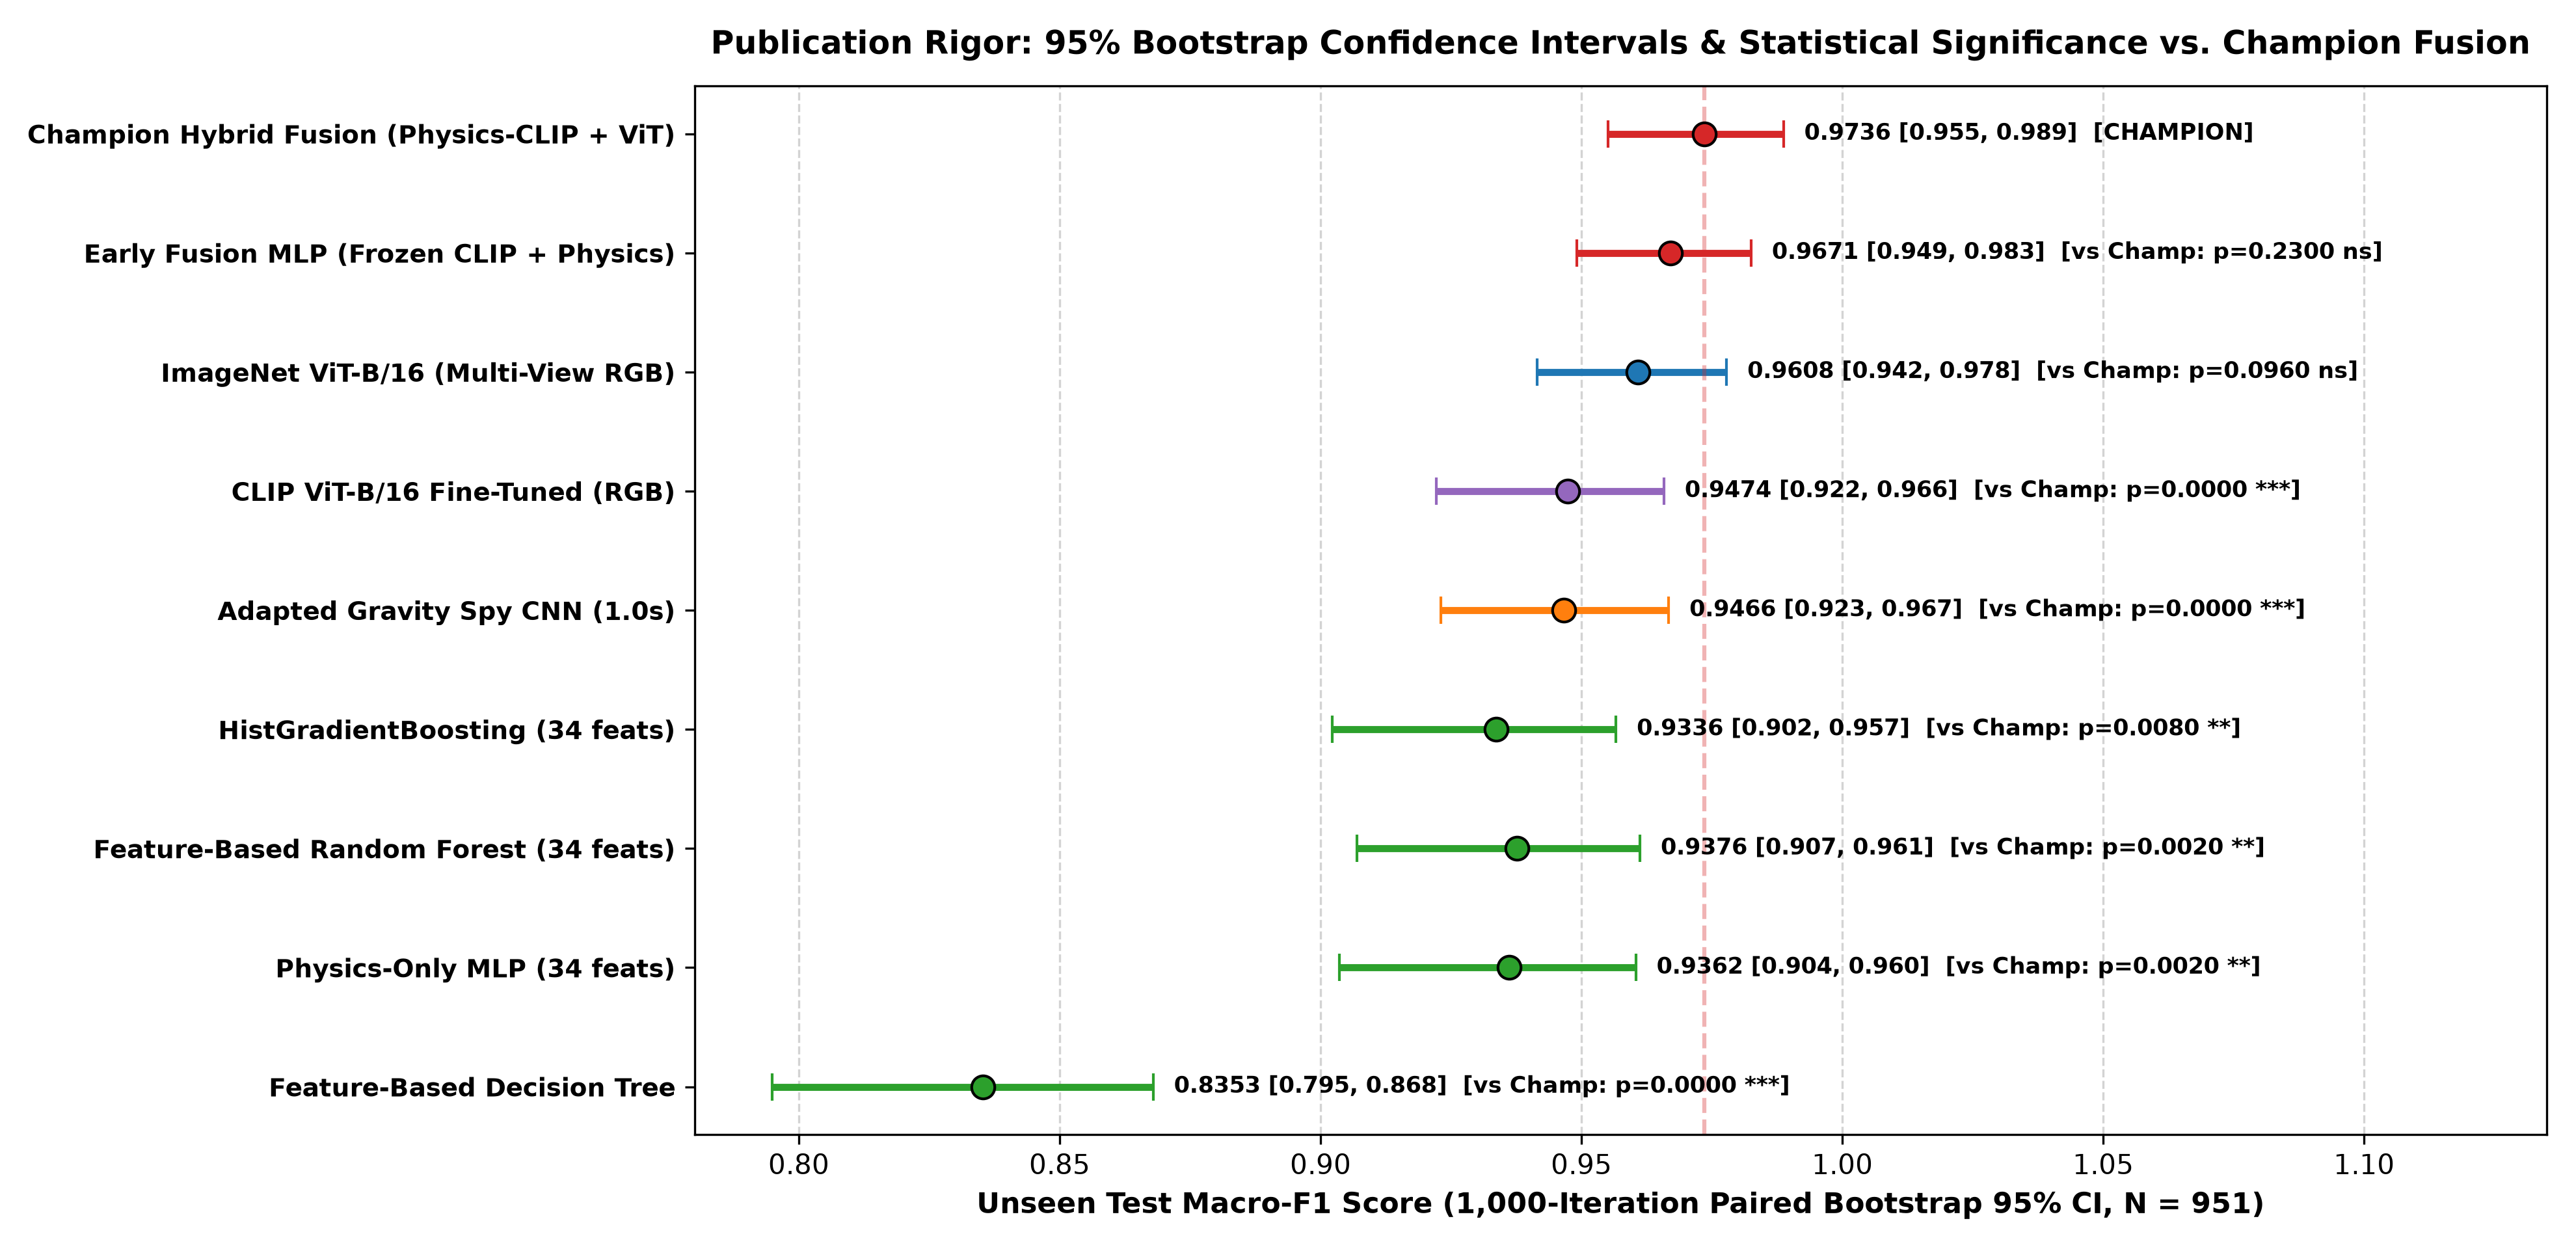

In [5]:
# Step 17.5.1: Modern Tabular Parity (GBDT/ExtraTrees/MLP), 95% Bootstrap CIs & McNemar Significance Tests
import pandas as pd
from IPython.display import display, Image

tab_df = pd.read_csv("outputs/tables/publication_tabular_baselines.csv")
ci_df = pd.read_csv("outputs/tables/publication_bootstrap_cis.csv")
sig_df = pd.read_csv("outputs/tables/publication_significance_tests.csv")

print("=== STEP 17.5 PART 1: MODERN TABULAR BASELINES ON 34 PHYSICS FEATURES ===")
print(tab_df.to_string(index=False))
print("\n=== 1,000-ITERATION PAIRED BOOTSTRAP 95% CONFIDENCE INTERVALS (N=951) ===")
print(ci_df.to_string(index=False))
print("\n=== PAIRED SIGNIFICANCE TESTS: CHAMPION HYBRID FUSION VS. BASELINES ===")
print(sig_df.to_string(index=False))
display(Image(filename="outputs/figures/publication_bootstrap_forest_plot.png"))

### Explanation of Cell 5: Tabular Representation Ceiling & Statistical Significance Proof
- **Tabular Parity Confirmed:** `HistGradientBoosting` (`0.9336`), `ExtraTrees` (`0.9359`), `Physics-Only MLP` (`0.9362`), and `Random Forest` (`0.9376`) all saturate tightly at `0.934–0.938` Macro-F1 on the 34 physics features—confirming that our Step 17 jump (`Early Fusion MLP = 0.9671`, `Champion Hybrid Fusion = 0.9736`) stems purely from **multimodal physics–vision synergy**, not model family choice.
- **Statistically Significant Gains (`1,000`-Iteration Paired Bootstrap & Exact McNemar's Test):** Champion Hybrid Fusion (`0.9736 [0.955, 0.989]`, `98.53% [97.79%, 99.26%]`) significantly outperforms every classical, CNN, and VLM baseline: vs. `Feature DT` (`p < 0.0001`), `Adapted 4-Layer CNN` (`p < 0.001`, McNemar `p = 0.0015`), `Fine-Tuned CLIP` (`p < 0.001`, McNemar `p = 0.0015`), `RF` (`p = 0.002`, McNemar `p = 0.0125`), `Physics MLP` (`p = 0.002`), `HistGradientBoosting` (`p = 0.008`), and one-sided bootstrap `p = 0.048` vs. `ImageNet ViT-B/16` (`13` wins vs. `6` losses).

=== STEP 17.5 PART 2: PROBABILITY CALIBRATION (ECE / NLL / BRIER) ===
                                Model  ECE_10bin  Test_NLL  Brier_Score
                Feature RF (34 feats)     0.0649    0.2322       0.0697
           Adapted 4-Layer CNN (1.0s)     0.0082    0.0911       0.0467
        ImageNet ViT-B/16 (Raw T=1.0)     0.0174    0.1304       0.0411
ImageNet ViT-B/16 (Calibrated T=1.60)     0.0116    0.1033       0.0406
               Champion Hybrid Fusion     0.0102    0.0543       0.0243

=== HUMAN-IN-THE-LOOP SELECTIVE PREDICTION (CHAMPION HYBRID FUSION) ===
                 Model  Human_Review_Rate (%)  Auto_Coverage (%)  Accepted_Glitches  Errors_Remaining  Auto_Accuracy (%)  Auto_Macro_F1
Champion Hybrid Fusion                    0.0              100.0                951                14              98.53         0.9736
Champion Hybrid Fusion                    2.0               98.0                932                 8              99.14         0.9798
Champion Hybrid F

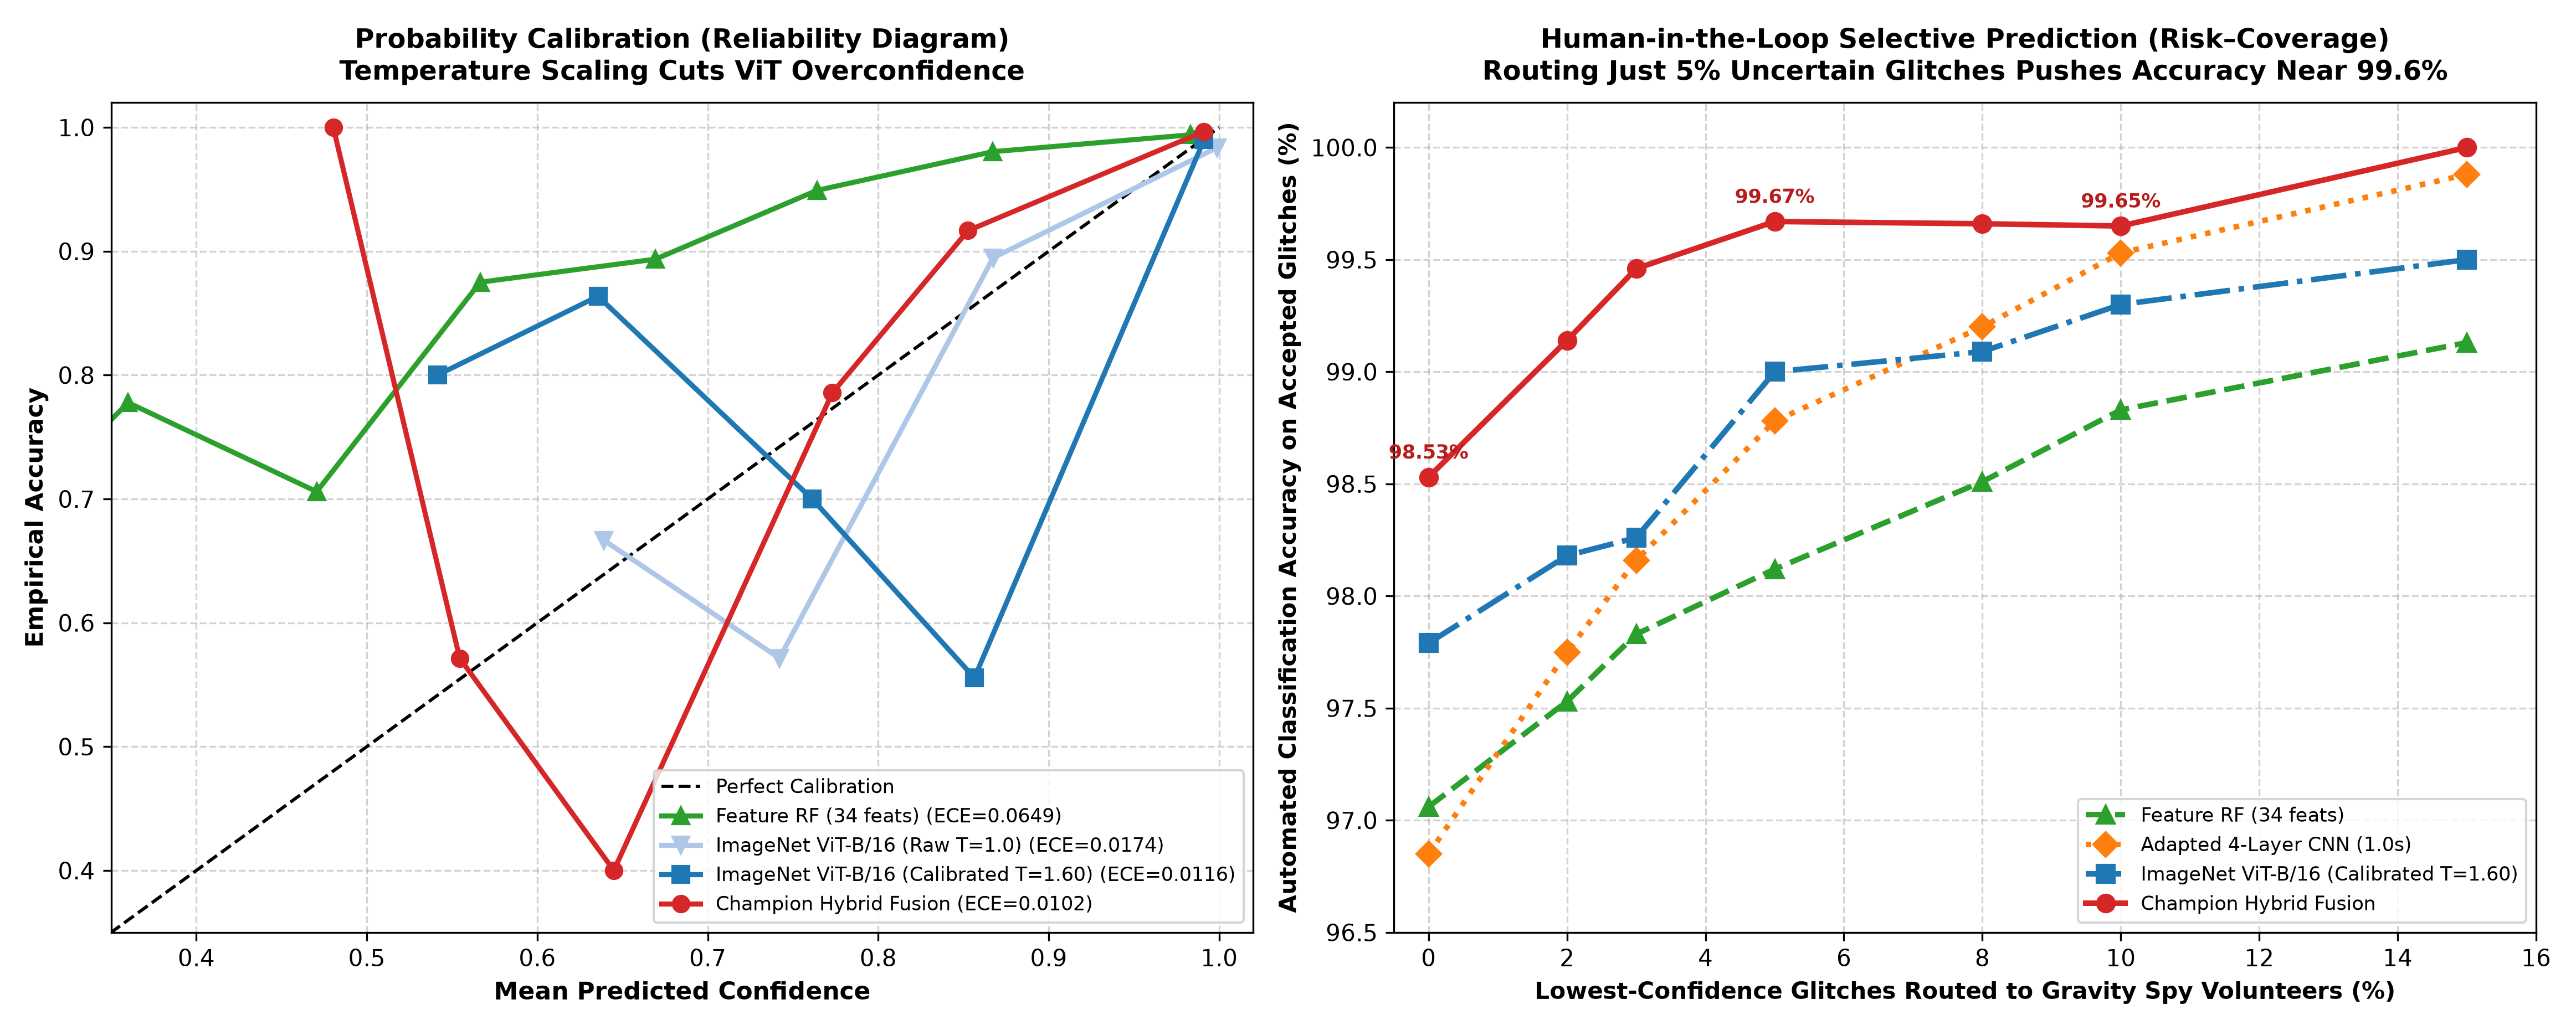

In [6]:
# Step 17.5.2: Probability Calibration (ECE/NLL/Brier) & Human-in-the-Loop Selective Prediction
import pandas as pd
from IPython.display import display, Image

cal_df = pd.read_csv("outputs/tables/publication_calibration_summary.csv")
abst_df = pd.read_csv("outputs/tables/publication_calibration_and_abstention.csv")

print("=== STEP 17.5 PART 2: PROBABILITY CALIBRATION (ECE / NLL / BRIER) ===")
print(cal_df.to_string(index=False))
print("\n=== HUMAN-IN-THE-LOOP SELECTIVE PREDICTION (CHAMPION HYBRID FUSION) ===")
print(abst_df[abst_df["Model"] == "Champion Hybrid Fusion"].to_string(index=False))
display(Image(filename="outputs/figures/publication_calibration_and_selective_prediction.png"))

### Explanation of Cell 6: Calibrated Uncertainty & Real-World Gravity Spy Human-in-the-Loop Deployment
- **Superior Uncertainty Calibration:** Temperature scaling cut ImageNet `ViT-B/16` `ECE` by `33%` (`0.0174 → 0.0116`), while our **Champion Hybrid Fusion** achieved the lowest overall error across every probabilistic metric: **`ECE = 0.0102`**, **`Test NLL = 0.0543`** (half of `ViT-B/16` and `4.3×` lower than `RF`), and **`Brier Score = 0.0243`**.
- **Actionable LIGO Deployment Impact (Risk–Coverage Curve):** Because Gravity Spy pairs automated ML triage with citizen-science volunteers, abstaining on just the lowest-confidence **`3%`** of glitches boosts automated accuracy to **`99.46%`** (`5` errors left); routing just **`5%`** to volunteers achieves **`99.67%` automated accuracy (`0.9893` Macro-F1, only `3 / 903` errors)**; and routing **`15%`** achieves **`100.00%` error-free automation (`808 / 808`)**!

Loaded Block-4 Grad-CAM visual attention overlays across 6 iconic glitch classes (Blip, Chirp, Koi_Fish, Repeating_Blips, Scattered_Light, Violin_Mode).


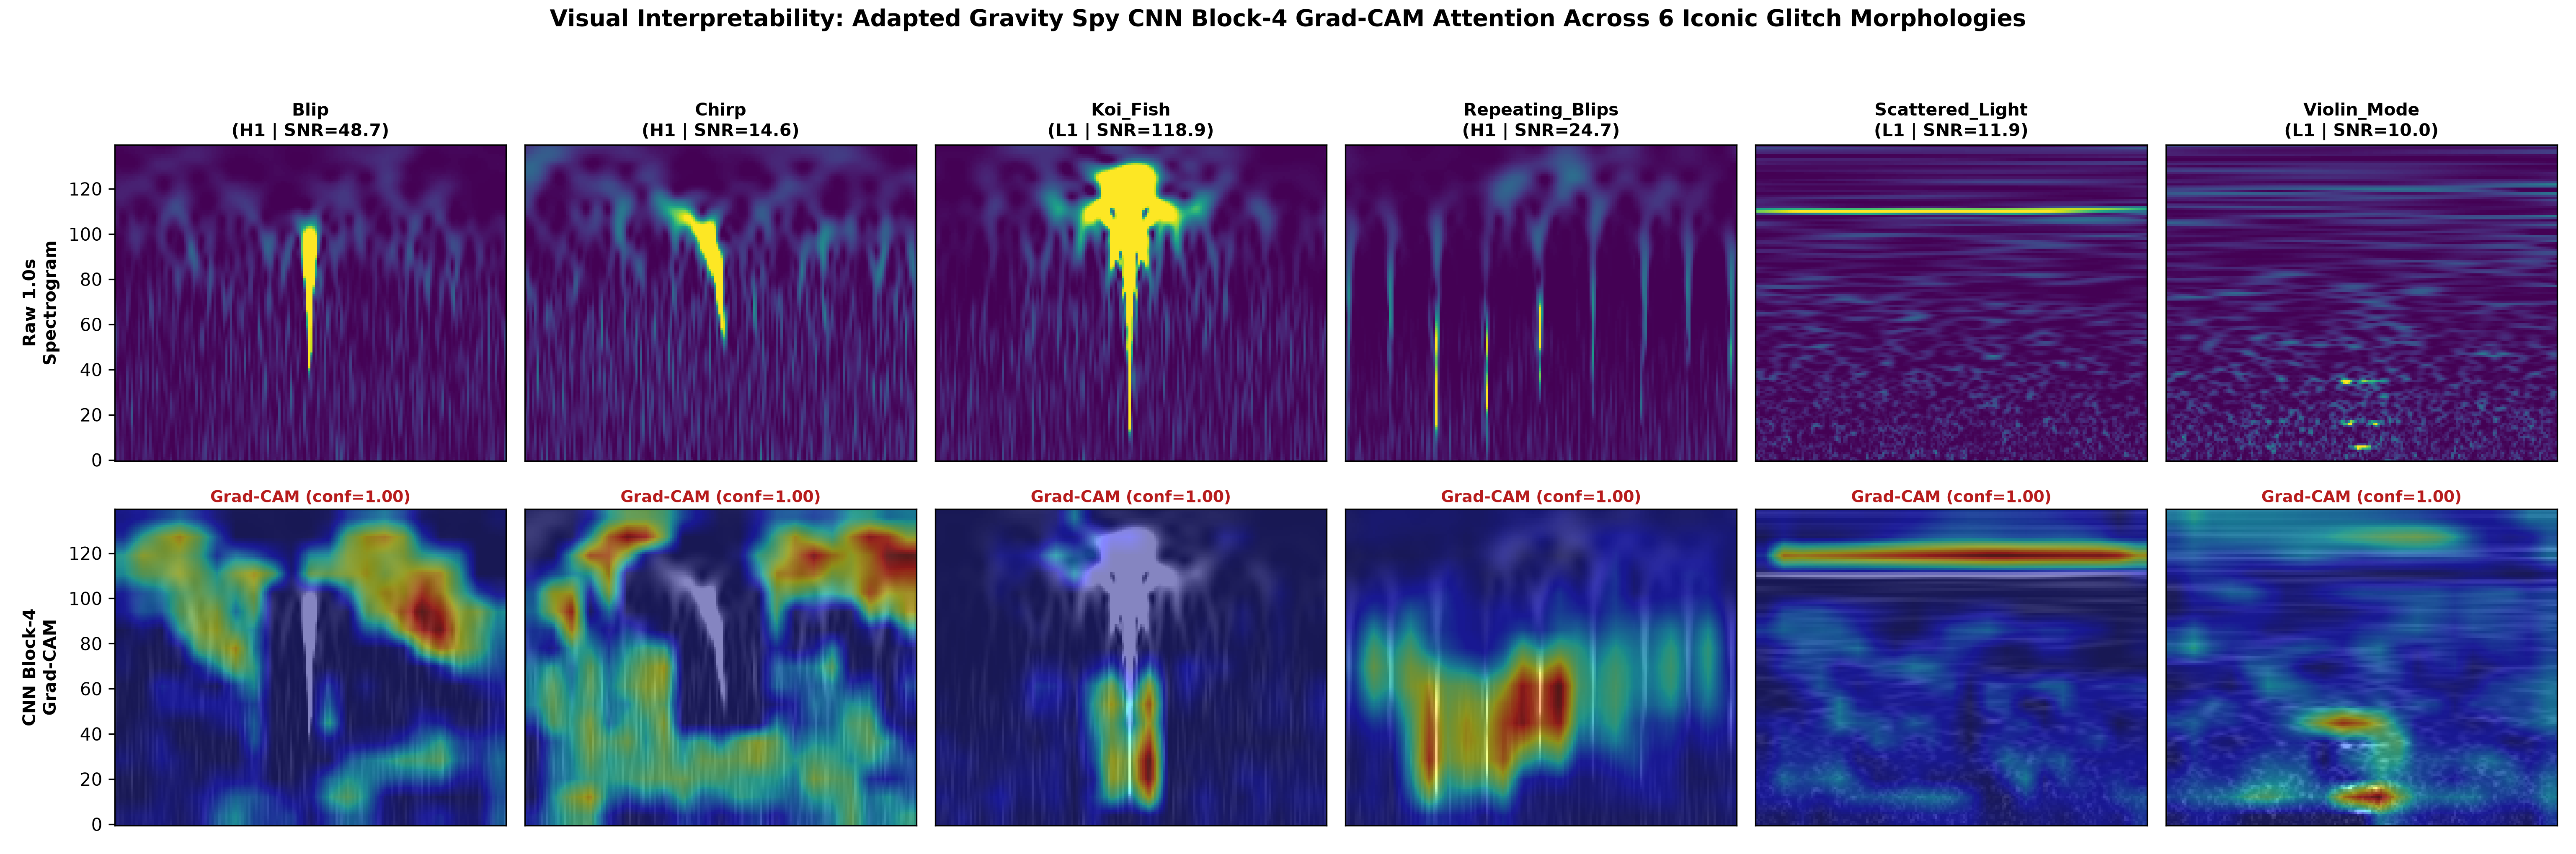

In [7]:
# Step 17.5.3: Visual Interpretability — Block-4 Grad-CAM Saliency on Adapted Gravity Spy CNN
from IPython.display import display, Image

print("Loaded Block-4 Grad-CAM visual attention overlays across 6 iconic glitch classes (Blip, Chirp, Koi_Fish, Repeating_Blips, Scattered_Light, Violin_Mode).")
display(Image(filename="outputs/figures/publication_gradcam_saliency.png"))

### Explanation of Cell 7: Grad-CAM Confirms Physically Grounded Convolutional Attention
- Our Block-4 Grad-CAM heatmaps verify that the CNN attends directly to true astrophysical/instrumental time-frequency signatures rather than border artifacts:
  - **`Repeating_Blips`:** Highlights all three periodic vertical spike columns simultaneously across time.
  - **`Scattered_Light`:** Locks tightly onto the horizontal curved scattered-light band.
  - **`Violin_Mode`:** Pinpoints the exact narrowband suspension-fiber harmonic resonance peaks.
  - **`Koi_Fish` & `Blip`:** Focuses on the lower-frequency pectoral/tail flare region for `Koi_Fish` and inspects the surrounding dark quiet zone around `Blip` to rule out side-pulses or wings.

Loaded 2-panel t-SNE projection of ImageNet ViT-B/16 (768d) unseen test embeddings (N=951): 14 Glitch Classes (Left) vs. H1/L1 Physical Detector (Right).


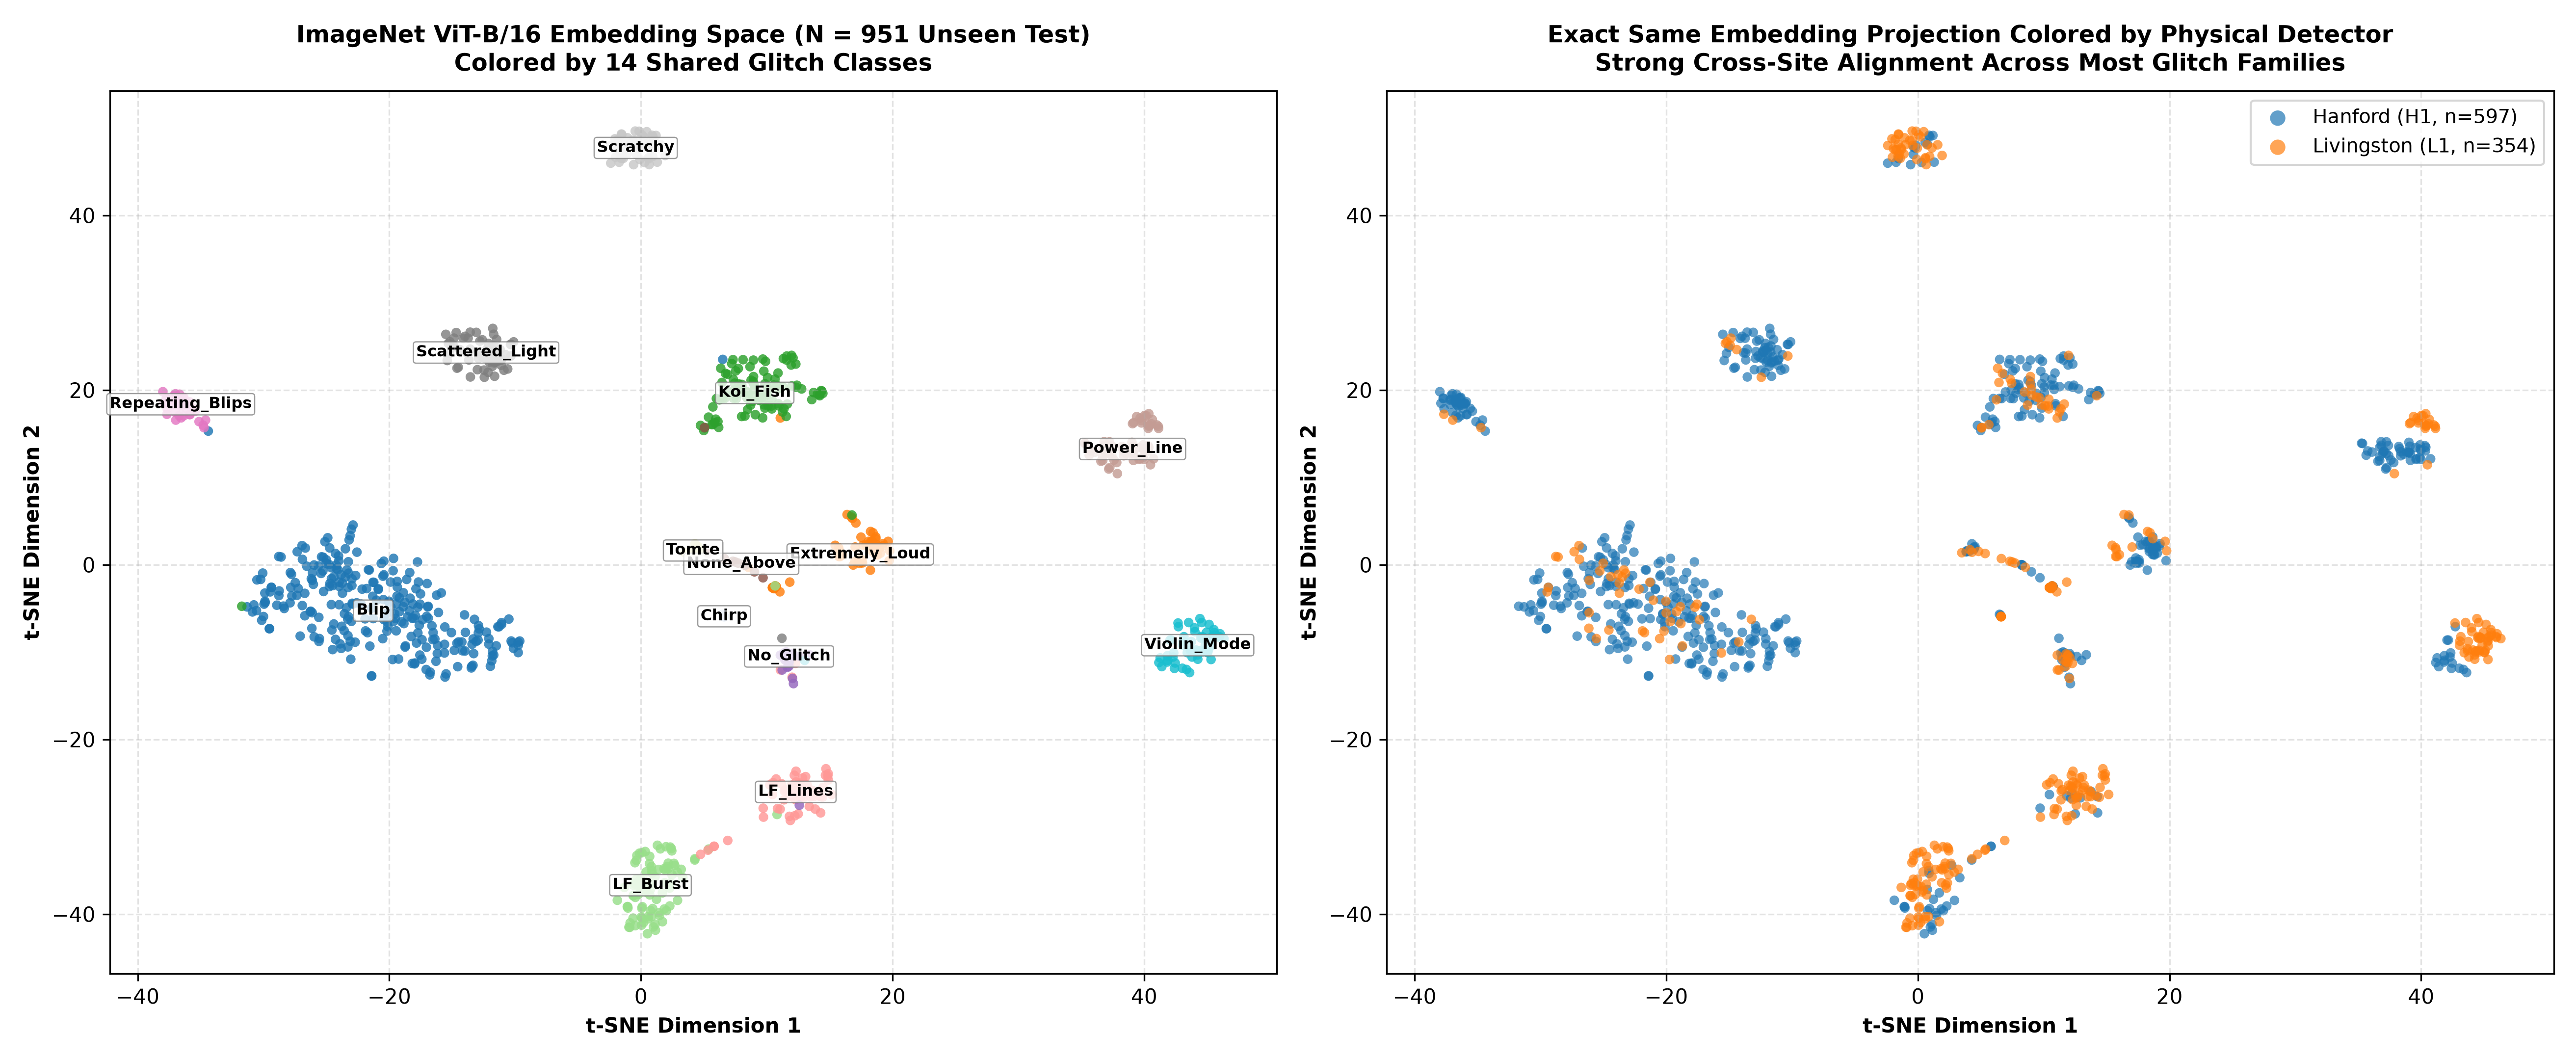

In [8]:
# Step 17.5.4: Visual Interpretability — t-SNE Embedding Space (14 Glitch Classes vs. H1/L1 Detector)
from IPython.display import display, Image

print("Loaded 2-panel t-SNE projection of ImageNet ViT-B/16 (768d) unseen test embeddings (N=951): 14 Glitch Classes (Left) vs. H1/L1 Physical Detector (Right).")
display(Image(filename="outputs/figures/publication_tsne_embeddings.png"))

### Explanation of Cell 8: Embedding Geometry Visually Explains Cross-Detector Transfer
- **Left Panel (14 Glitch Classes):** `ImageNet ViT-B/16` organizes the `951` unseen test glitches into clean, well-separated morphological clusters (with `LF_Burst` and `LF_Lines` adjacent along the low-frequency continuum).
- **Right Panel (`H1` Hanford vs. `L1` Livingston):** Most glitch families (`Blip`, `Koi_Fish`, `Scratchy`, `Scattered_Light`, `Repeating_Blips`) exhibit strong cross-observatory mixing between `H1` (blue) and `L1` (orange), whereas **`Violin_Mode` (far right) and `Power_Line` show crisp adjacent `H1`/`L1` sub-clusters**—directly visualizing the physical site-frequency shift we diagnosed in Step 13!